# DeepSentinel: Deepfake Detection with EfficientNet-B4

Binary classifier for detecting manipulated faces, built on a fine-tuned EfficientNet-B4.

**Pipeline**
1. Load pre-cropped face images with identity-isolated train/validation/test splits
2. Class-balanced sampling and augmentation
3. Fine-tuning of an ImageNet-pretrained EfficientNet-B4 with mixed-precision training
4. Evaluation with ROC AUC, accuracy, precision, recall, and F1
5. Model interpretability with Grad-CAM

**Dataset:** [Deepfake Identity Isolated Dataset](https://huggingface.co/datasets/ThinothW/Deepfake-Identity-Isolated-Dataset-PreP) (CC BY 4.0), roughly 143K face crops at 260×260 with no identity overlap across splits.

**Environment:** Python 3.10+, PyTorch with CUDA, single GPU. Training is checkpointed every epoch and resumes automatically.

## 1. Dependencies

In [ ]:
%pip install -q --no-cache-dir torch torchvision --index-url https://download.pytorch.org/whl/cu126
%pip install -q --no-cache-dir timm wandb grad-cam scikit-learn datasets hf_xet brotli matplotlib

## 2. Configuration

In [ ]:
import os
import random
from pathlib import Path

SCRATCH = Path(os.environ.get("RCAC_SCRATCH", Path.home()))
ROOT = Path(os.environ.get("DEEPSENTINEL_ROOT", SCRATCH / "deepsentinel"))
CKPT = ROOT / "checkpoints"
os.environ.setdefault("HF_HOME", str(SCRATCH / "hf_cache"))
for p in (ROOT, CKPT):
    p.mkdir(parents=True, exist_ok=True)

# Data
DATASET_ID = "ThinothW/Deepfake-Identity-Isolated-Dataset-PreP"
N_TRAIN_PER_CLASS = 10_000   # None uses the full split
N_EVAL_PER_CLASS = 2_000     # applied to validation and test

# Training
IMG_SIZE = 224
BATCH = 64
EPOCHS = 5
LR = 3e-4
SEED = 42

# Logging
USE_WANDB = True
WANDB_PROJECT = "deepsentinel"
os.environ["WANDB_NOTEBOOK_NAME"] = "deepsentinel.ipynb"

random.seed(SEED)

## 3. Data

Each split is subsampled to an equal number of real and fake images. Labels are remapped so that `1` denotes a manipulated face.

In [ ]:
import numpy as np
from datasets import load_dataset

raw = load_dataset(DATASET_ID)
label_names = raw["train"].features["label"].names
FAKE_IDX = [n.lower() for n in label_names].index("fake")
print(f"Splits: {({k: len(v) for k, v in raw.items()})} | Labels: {label_names}")


def balanced_subset(ds, n_per_class, seed=SEED):
    if n_per_class is None:
        return ds
    labels = np.asarray(ds["label"])
    rng = np.random.default_rng(seed)
    idx = np.concatenate([
        rng.choice(np.flatnonzero(labels == c), min(n_per_class, (labels == c).sum()), replace=False)
        for c in np.unique(labels)
    ])
    return ds.select(rng.permutation(idx))


val_key = "validation" if "validation" in raw else "val"
splits = {
    "train": balanced_subset(raw["train"], N_TRAIN_PER_CLASS),
    "val": balanced_subset(raw[val_key], N_EVAL_PER_CLASS),
    "test": balanced_subset(raw["test"], N_EVAL_PER_CLASS),
}
for name, ds in splits.items():
    fake = int((np.asarray(ds["label"]) == FAKE_IDX).sum())
    print(f"{name:>5}: real={len(ds) - fake}, fake={fake}")

Splits: {'train': 99910, 'validation': 21611, 'test': 21316} | Labels: ['fake', 'real']
train: real=10000, fake=10000
  val: real=2000, fake=2000
 test: real=2000, fake=2000


## 4. Data Pipeline

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = T.Compose([
    T.CenterCrop(208),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(),
    T.RandomApply([T.ColorJitter(0.2, 0.2, 0.2, 0.05)], p=0.5),
    T.RandomApply([T.GaussianBlur(5)], p=0.2),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.2),
])
eval_tf = T.Compose([
    T.CenterCrop(208),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

class FaceDataset(Dataset):
    def __init__(self, hf_ds, transform):
        self.ds = hf_ds
        self.transform = transform

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        row = self.ds[idx]
        img = self.transform(row["image"].convert("RGB"))
        return img, torch.tensor(float(row["label"] == FAKE_IDX))


num_workers = min(8, os.cpu_count())
train_ds = FaceDataset(splits["train"], train_tf)
val_ds = FaceDataset(splits["val"], eval_tf)
test_ds = FaceDataset(splits["test"], eval_tf)

train_dl = DataLoader(train_ds, BATCH, shuffle=True, num_workers=num_workers,
                      pin_memory=True, drop_last=True, persistent_workers=True)
val_dl = DataLoader(val_ds, BATCH * 2, num_workers=num_workers, pin_memory=True)
test_dl = DataLoader(test_ds, BATCH * 2, num_workers=num_workers, pin_memory=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)} | Device: {device}")

Train: 20000 | Val: 4000 | Test: 4000 | Device: cuda


## 5. Model

EfficientNet-B4 (ImageNet-pretrained, via `timm`) with a single-logit head. Optimized with AdamW and a one-cycle learning rate schedule. Training state is restored from the latest checkpoint if one exists.

In [ ]:
import timm
import torch.nn as nn
from sklearn.metrics import roc_auc_score, accuracy_score, precision_recall_fscore_support

model = timm.create_model("efficientnet_b4", pretrained=True, num_classes=1).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, total_steps=EPOCHS * len(train_dl), pct_start=0.1
)
scaler = torch.amp.GradScaler("cuda")
criterion = nn.BCEWithLogitsLoss()

start_epoch, best_auc, run_id = 0, 0.0, None
last_ckpt = CKPT / "last.pt"
if last_ckpt.exists():
    state = torch.load(last_ckpt, map_location=device)
    model.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    scheduler.load_state_dict(state["scheduler"])
    scaler.load_state_dict(state["scaler"])
    start_epoch, best_auc, run_id = state["epoch"] + 1, state["best_auc"], state.get("run_id")
    print(f"Resumed from epoch {start_epoch} (best val AUC {best_auc:.4f})")

if USE_WANDB:
    import wandb
    run = wandb.init(
        project=WANDB_PROJECT, id=run_id, resume="allow",
        config=dict(model="efficientnet_b4", dataset=DATASET_ID, img_size=IMG_SIZE,
                    batch=BATCH, lr=LR, epochs=EPOCHS, n_train_per_class=N_TRAIN_PER_CLASS),
    )
    run_id = run.id

## 6. Training

Model selection uses validation ROC AUC.

In [ ]:
from tqdm.auto import tqdm


@torch.no_grad()
def evaluate(loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            p = torch.sigmoid(model(x.to(device, non_blocking=True)).squeeze(1))
        probs += p.float().cpu().tolist()
        labels += y.tolist()
    probs, labels = np.array(probs), np.array(labels)
    preds = probs > 0.5
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    return {
        "auc": roc_auc_score(labels, probs),
        "accuracy": accuracy_score(labels, preds),
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


for epoch in range(start_epoch, EPOCHS):
    model.train()
    running_loss = 0.0
    pbar = tqdm(train_dl, desc=f"Epoch {epoch + 1}/{EPOCHS}")
    for step, (x, y) in enumerate(pbar):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = criterion(model(x).squeeze(1), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item()
        if step % 50 == 0:
            pbar.set_postfix(loss=f"{running_loss / (step + 1):.4f}")
            if USE_WANDB:
                wandb.log({"train/loss": loss.item(), "train/lr": scheduler.get_last_lr()[0]})

    metrics = evaluate(val_dl)
    print(f"Epoch {epoch + 1}: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items()))
    if USE_WANDB:
        wandb.log({f"val/{k}": v for k, v in metrics.items()} | {"epoch": epoch + 1})

    if metrics["auc"] > best_auc:
        best_auc = metrics["auc"]
        torch.save(model.state_dict(), CKPT / "best.pt")

    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "epoch": epoch,
        "best_auc": best_auc,
        "run_id": run_id,
    }, last_ckpt)

Epoch 1: auc=0.8925, accuracy=0.8053, precision=0.8048, recall=0.8060, f1=0.8054


Epoch 2: auc=0.9344, accuracy=0.8518, precision=0.8533, recall=0.8495, f1=0.8514


Epoch 3: auc=0.9504, accuracy=0.8720, precision=0.8800, recall=0.8615, f1=0.8706


Epoch 4: auc=0.9541, accuracy=0.8752, precision=0.8819, recall=0.8665, f1=0.8741


Epoch 5: auc=0.9543, accuracy=0.8742, precision=0.8950, recall=0.8480, f1=0.8709


## 7. Test Evaluation

In [ ]:
model.load_state_dict(torch.load(CKPT / "best.pt", map_location=device))
test_metrics = evaluate(test_dl)
print(", ".join(f"{k}={v:.4f}" for k, v in test_metrics.items()))

if USE_WANDB:
    wandb.log({f"test/{k}": v for k, v in test_metrics.items()})

auc=0.9557, accuracy=0.8878, precision=0.9020, recall=0.8700, f1=0.8857


## 8. Interpretability (Grad-CAM)

Class activation maps from the final convolutional layer, highlighting facial regions that drive the manipulation prediction.

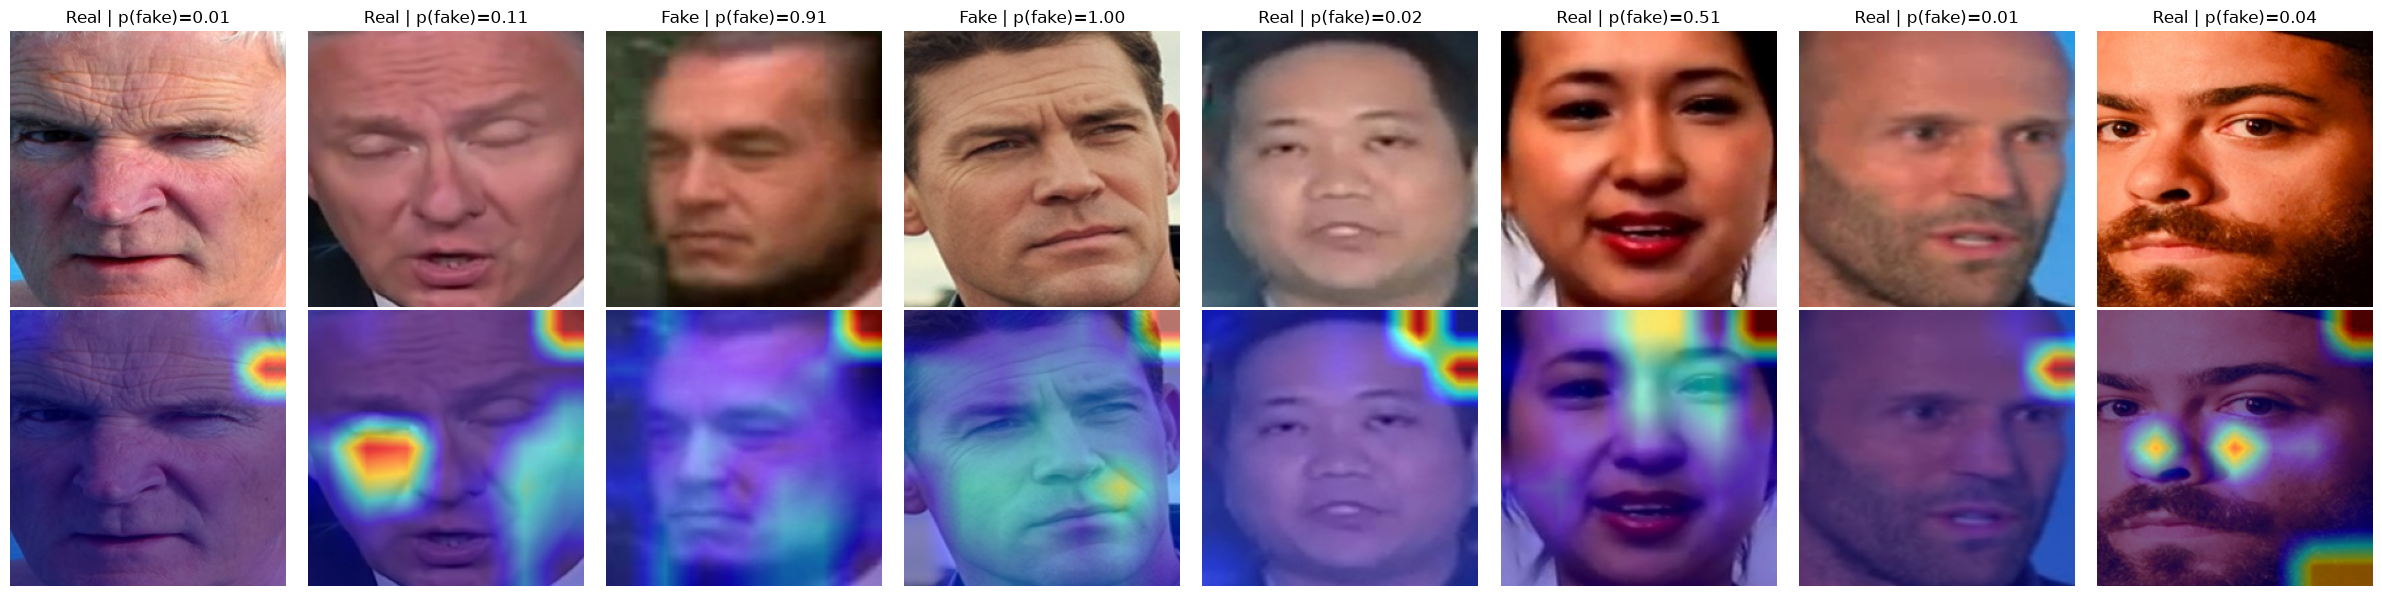

In [ ]:
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import BinaryClassifierOutputTarget

model.eval()
cam = GradCAM(model=model, target_layers=[model.conv_head])
sample_idx = random.sample(range(len(splits["test"])), 8)

fig, axes = plt.subplots(2, 8, figsize=(24, 6))
for i, idx in enumerate(sample_idx):
    row = splits["test"][idx]
    pil = T.CenterCrop(208)(row["image"].convert("RGB")).resize((IMG_SIZE, IMG_SIZE))
    img = np.asarray(pil, dtype=np.float32) / 255.0
    x = eval_tf(pil).unsqueeze(0).to(device)
    prob = torch.sigmoid(model(x)).item()
    heatmap = cam(input_tensor=x, targets=[BinaryClassifierOutputTarget(1)])[0]

    is_fake = row["label"] == FAKE_IDX
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"{'Fake' if is_fake else 'Real'} | p(fake)={prob:.2f}")
    axes[1, i].imshow(show_cam_on_image(img, heatmap, use_rgb=True))
    for ax in axes[:, i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(ROOT / "gradcam.png", dpi=120, bbox_inches="tight")
plt.show()

if USE_WANDB:
    wandb.log({"gradcam": wandb.Image(str(ROOT / "gradcam.png"))})

## 9. Export

In [ ]:
export_path = ROOT / "deepsentinel_effb4.pt"
torch.save(model.state_dict(), export_path)
print(f"Saved weights to {export_path}")

if USE_WANDB:
    wandb.finish()

Saved weights to /scratch/scholar/chaud124/deepsentinel/deepsentinel_effb4.pt


## 10. Robustness Check

Grad-CAM shows recurring activation in the top-right corner. Masking that region at test time leaves ROC AUC essentially unchanged, which indicates the activation is a boundary effect of the low-resolution final feature map rather than a learned shortcut.

In [ ]:
@torch.no_grad()
def evaluate_masked(loader, frac=0.25):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        x = x.clone()
        h, w = x.shape[-2:]
        x[..., : int(h * frac), w - int(w * frac):] = 0
        with torch.autocast("cuda", dtype=torch.float16):
            p = torch.sigmoid(model(x.to(device)).squeeze(1))
        probs += p.float().cpu().tolist()
        labels += y.tolist()
    return roc_auc_score(labels, probs)

print(f"Original AUC: {test_metrics['auc']:.4f}")
print(f"Top-right corner masked AUC: {evaluate_masked(test_dl):.4f}")

Original AUC: 0.9557
Top-right corner masked AUC: 0.9554
